# Time-series forecasting with SAP-RPT-TS on SAP AI Core

**SAP-RPT-TS** (`sap-rpt-ts`) is SAP's pretrained time-series foundation model. Like the tabular RPT models it learns *in context*: you send recent history (plus optional covariates) and receive a probabilistic multi-step forecast, with no training step.

| Item | Value |
|---|---|
| Deployment | scenario `foundation-models`, executable `aicore-sap`, model `sap-rpt-ts`, version `1` |
| Endpoint | `POST {deployment_url}/predict` |
| Body | `{"horizon": int, "data": [series, ...], "options": {...}}` |
| History per series | up to 8,192 points (older points are truncated) |
| Horizon | up to 1,024 steps |
| Targets + covariates | keep below 128 per series |

**AI Core vs Playground.** The RPT Playground's `POST /api/forecast` takes the same body, but caps the horizon at 90 and wraps the result in `{"forecast": ..., "delay": ...}`. On AI Core the forecast fields come back at the top level, together with `usage` (billed time points). Unlike the tabular models there is no `status.code` envelope: errors are plain HTTP 400/422 with a FastAPI `detail` message.

The SAP AI SDK has no SAP-RPT-TS client yet, so `rpt_ts_client.py` adds a thin one on top of `rpt_client_api.py` (same authentication and deployment discovery).

Contents:

1. Request/response contract on a tiny example.
2. Deterministic post-processing rules.
3. Backtest on real data: 13 regional series, `cross_learning`, `enhanced_forecast`, comparison with a seasonal-naive baseline.
4. Quantiles and the `point_forecast` method.
5. Hierarchical forecasting (region and country) with reconciled totals.

## 1. Setup

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import find_dotenv, load_dotenv
from tqdm.auto import tqdm

from rpt_client_api import RPTAPIError
from rpt_ts_client import RPTTSClientAPI, forecast_to_frame, hierarchy_to_frame

_ = load_dotenv(find_dotenv(usecwd=True))
client = RPTTSClientAPI()  # resolves the running sap-rpt-ts deployment

## 2. The contract on a tiny example

This is the example from the RPT Playground documentation (illustrative numbers): one monthly series with four observations, a `temperature` covariate known for the past and for the three forecast months, and a 90% confidence interval.

Per series:

* `target`: history; a flat list for one target, a list of lists for several targets on the same timeline; `null` marks a missing value.
* `timestamp` (optional): same length as the target; `int`, `YYYY-MM-DD`, `YYYY-MM-DD HH:MM:SS`, LONGDATE or `HH:MM:SS`. Regular spacing is expected; up to 20% filled gaps are tolerated.
* `past_covariates`: same length as the target. `future_covariates`: length `horizon`, and every key must also be a past covariate.

In [2]:
example_request = {
    "horizon": 3,
    "data": [
        {
            "timestamp": ["2024-01-01", "2024-02-01", "2024-03-01", "2024-04-01"],
            "target": [120, 135, 128, 142],
            "past_covariates": {"temperature": [15, 18, 17, 21]},
            "future_covariates": {"temperature": [22, 24, 23]},
        }
    ],
    "options": {"confidence_interval": 0.9},
}
example_response = client.forecast(example_request)
print(json.dumps(example_response, indent=2))

{
  "all_null_targets": [],
  "confidence_interval_output": [
    [
      [
        [
          122.7403564453125,
          126.0583724975586,
          124.12074279785156
        ],
        [
          178.7145233154297,
          204.69876098632812,
          210.86856079101562
        ]
      ]
    ]
  ],
  "detected_interval": [
    {
      "unit": "month",
      "value": 1
    }
  ],
  "group_results": null,
  "hierarchical_result": null,
  "quantile_result": null,
  "result": [
    [
      [
        147.21084594726562,
        155.68292236328125,
        154.62445068359375
      ]
    ]
  ],
  "result_timestamp": [
    [
      "2024-05-01",
      "2024-06-01",
      "2024-07-01"
    ]
  ],
  "selected_quantile_result": null,
  "usage": {
    "input_time_points": 11,
    "output_time_points": 3
  }
}


All arrays are nested by **series, then target (variate), then step**:

* `result[s][v][step]`: point forecast (median by default).
* `confidence_interval_output[s][v][0|1][step]`: lower / upper bound (80% if `confidence_interval` is not set; `null` disables it).
* `result_timestamp`, `detected_interval`: future timestamps and the inferred sampling interval (both `null` without timestamps).
* `usage`: input and output time points, the billing unit.

`forecast_to_frame` flattens this into a table:

In [3]:
forecast_to_frame(example_response, series_ids=["example"])

,series,variate,step,timestamp,point,lower,upper
0,example,0,1,2024-05-01,147.210846,122.740356,178.714523
1,example,0,2,2024-06-01,155.682922,126.058372,204.698761
2,example,0,3,2024-07-01,154.624451,124.120743,210.868561


Validation errors are returned by the service and surfaced by the client as `RPTAPIError` with the server message, for example a future covariate of the wrong length:

In [4]:
broken = json.loads(json.dumps(example_request))
broken["data"][0]["future_covariates"]["temperature"] = [22, 24]  # horizon is 3
try:
    client.forecast(broken)
except RPTAPIError as error:
    print("HTTP", error.http_status, "->", str(error)[:300])

HTTP 400 -> RPT-TS /predict failed with HTTP 400: future_covariates.temperature length must match horizon


## 3. Deterministic rules

`options.rules` override forecast values when a future covariate meets a condition, for example "zero demand on days the site is closed". Each rule has `covariate`, `operator` (`==`, `!=`, `>=`, `<=`, `>`, `<`), `threshold` and `forecast_value`.

Like `clip_min`/`clip_max`, rules change only the point forecast (`result`), not the interval or quantile outputs, so a rule-adjusted point can fall outside the reported interval. The data below is again illustrative.

In [5]:
rules_request = {
    "horizon": 3,
    "data": [
        {
            "timestamp": ["2024-01-01", "2024-02-01", "2024-03-01", "2024-04-01", "2024-05-01", "2024-06-01"],
            "target": [120, 135, 128, 142, 150, 149],
            "past_covariates": {"closed": [0, 0, 0, 0, 0, 0]},
            "future_covariates": {"closed": [0, 1, 0]},
        }
    ],
    "options": {"rules": [{"covariate": "closed", "operator": "==", "threshold": 1, "forecast_value": 0}]},
}
forecast_to_frame(client.forecast(rules_request))

,series,variate,step,timestamp,point,lower,upper
0,0,0,1,2024-07-01,150.189560,135.471664,163.727234
1,0,0,2,2024-08-01,0.000000,135.865326,175.126480
2,0,0,3,2024-09-01,154.103073,132.270721,180.905701


## 4. Real data: monthly overnight stays per region

`data/OVERNIGHTSTAYS.csv` holds public Swiss hotel statistics (Federal Statistical Office, dataset px-x-1003020000_103): overnight stays per tourism region and guests' country of residence, January 2022 to May 2024. Summing over countries gives **13 regional monthly series of 29 points**.

That is a short history (less than two and a half seasons). SAP recommends providing as much history as possible, so this dataset is a demanding test.

(13, 29)


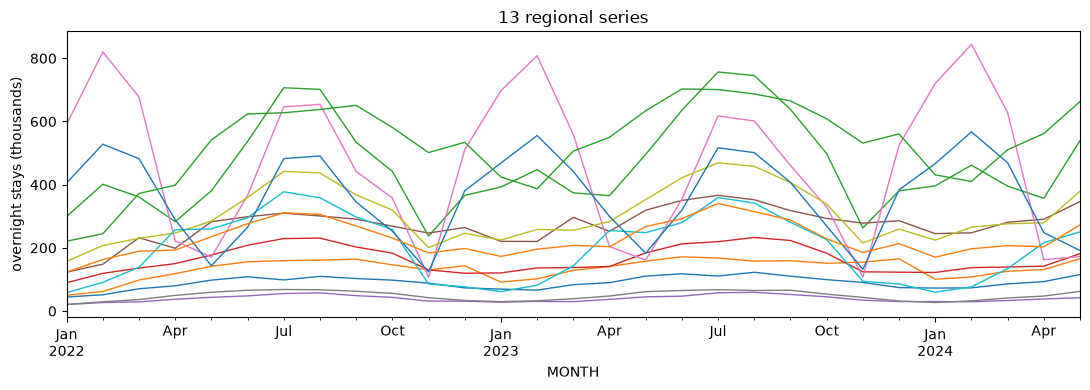

In [6]:
stays = pd.read_csv("data/OVERNIGHTSTAYS.csv", encoding="utf-8-sig")
stays["MONTH"] = pd.to_datetime(stays["MONTH"], format="%d/%m/%Y")
regions = stays.groupby(["REGION", "MONTH"])["OVERNIGHTSTAYS"].sum().unstack("MONTH")
months = regions.columns
print(regions.shape)

ax = (regions.T / 1e3).plot(figsize=(11, 4), legend=False, linewidth=1)
ax.set_ylabel("overnight stays (thousands)")
ax.set_title("13 regional series")
plt.tight_layout()

## 5. Backtest against a seasonal-naive baseline

We hide the last `horizon` months, forecast them, and compare with the truth. The **seasonal-naive** baseline repeats the value of the same month one year earlier, a strong benchmark for seasonal tourism data.

`backtest` sends all 13 regions in one request. Options tested:

* `cross_learning`: learn across the series of the request jointly (they are related regions). Default `false`.
* `enhanced_forecast`: extra inference passes for accuracy; input time points are billed at 4x.
* `clip_min=0`: stays cannot be negative.

Metrics: MAE (stays), MAPE, and interval coverage (share of true values inside the 80% interval).

In [7]:
def backtest(horizon, options):
    '''Forecast the last `horizon` months of every region and score them.'''
    history = regions.iloc[:, :-horizon]
    actual = regions.iloc[:, -horizon:].to_numpy()
    request = {
        "horizon": horizon,
        "data": [
            {"timestamp": [m.strftime("%Y-%m-%d") for m in history.columns], "target": row.tolist()}
            for _, row in history.astype(float).iterrows()
        ],
        "options": {"clip_min": 0, "confidence_interval": 0.8, **options},
    }
    response = client.forecast(request)
    predicted = np.array([series[0] for series in response["result"]])
    lower = np.array([series[0][0] for series in response["confidence_interval_output"]])
    upper = np.array([series[0][1] for series in response["confidence_interval_output"]])
    return response, {
        "MAE": np.abs(predicted - actual).mean(),
        "MAPE": (np.abs(predicted - actual) / actual).mean(),
        "80% coverage": ((actual >= lower) & (actual <= upper)).mean(),
        "input points": response["usage"]["input_time_points"],
    }


def seasonal_naive(horizon):
    '''Score the same-month-last-year baseline on the same holdout.'''
    actual = regions.iloc[:, -horizon:].to_numpy()
    predicted = regions.iloc[:, -horizon - 12:-12].to_numpy()
    return {"MAE": np.abs(predicted - actual).mean(), "MAPE": (np.abs(predicted - actual) / actual).mean()}

In [8]:
HORIZON = 3
variants = {
    "default": {},
    "cross_learning": {"cross_learning": True},
    "enhanced_forecast": {"enhanced_forecast": True},
    "cross_learning + enhanced": {"cross_learning": True, "enhanced_forecast": True},
}
rows = {"seasonal naive": seasonal_naive(HORIZON)}
responses = {}
for name, options in tqdm(variants.items(), desc="variants"):
    responses[name], rows[name] = backtest(HORIZON, options)
pd.DataFrame(rows).T.round(3)

variants:   0%|          | 0/4 [00:00<?, ?it/s]

,MAE,MAPE,80% coverage,input points
seasonal naive,14449.821,0.057,NaN,NaN
default,11148.827,0.054,1.000,338.0
cross_learning,11526.721,0.057,0.974,338.0
enhanced_forecast,11847.687,0.055,1.000,1352.0
cross_learning + enhanced,10974.946,0.054,0.974,1352.0


### History length matters

The same comparison with a 6-month holdout leaves only 23 history points per series, less than two seasons. Check whether the model still beats the baseline:

In [9]:
long_rows = {"seasonal naive": seasonal_naive(6)}
for name in ["default", "cross_learning"]:
    _, long_rows[name] = backtest(6, variants[name])
pd.DataFrame(long_rows).T.round(3)

,MAE,MAPE,80% coverage,input points
seasonal naive,11953.859,0.051,NaN,NaN
default,19266.464,0.076,0.949,299.0
cross_learning,17139.769,0.064,0.962,299.0


### Plot

History, held-out truth, point forecast and 80% interval for three regions (cross-learning variant, 3-month holdout).

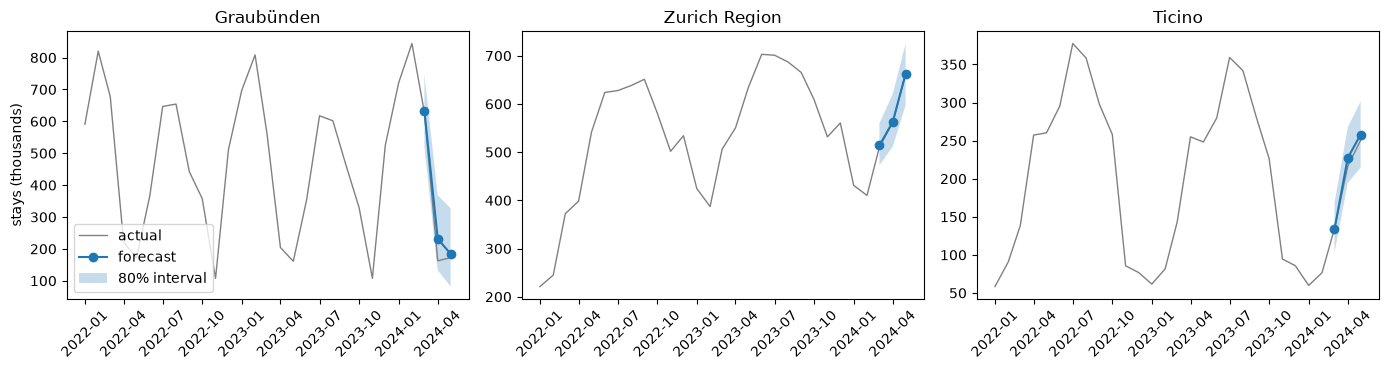

In [10]:
best = forecast_to_frame(responses["cross_learning"], series_ids=list(regions.index))
best["timestamp"] = pd.to_datetime(best["timestamp"])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for axis, region in zip(axes, ["Graubünden", "Zurich Region", "Ticino"]):
    part = best[best["series"] == region]
    axis.plot(months, regions.loc[region] / 1e3, color="grey", linewidth=1, label="actual")
    axis.plot(part["timestamp"], part["point"] / 1e3, color="tab:blue", marker="o", label="forecast")
    axis.fill_between(part["timestamp"], part["lower"] / 1e3, part["upper"] / 1e3, alpha=0.25, label="80% interval")
    axis.set_title(region)
    axis.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("stays (thousands)")
axes[0].legend()
plt.tight_layout()

## 6. Quantiles and the point-forecast method

* `output_quantile: true` returns the full fixed grid of **21 quantiles** (0.01 ... 0.99) in `quantile_result[s][v][21][step]`.
* `quantile_levels` returns only the requested quantiles in `selected_quantile_result`, and is also the integration grid for `point_forecast: "mean"`.
* `point_forecast`: `median` (default, MAE-optimal, robust) or `mean` (MSE-optimal, recommended for intermittent demand with many zeros; use a dense `quantile_levels` grid).

In [11]:
history = regions.iloc[:, :-HORIZON]
quantile_request = {
    "horizon": HORIZON,
    "data": [{"timestamp": [m.strftime("%Y-%m-%d") for m in history.columns],
              "target": history.loc["Graubünden"].astype(float).tolist()}],
    "options": {"output_quantile": True, "quantile_levels": [0.1, 0.5, 0.9], "confidence_interval": None},
}
quantile_response = client.forecast(quantile_request)
print("quantile_result shape:", np.array(quantile_response["quantile_result"]).shape)
print("selected_quantile_result shape:", np.array(quantile_response["selected_quantile_result"]).shape)

selected = np.array(quantile_response["selected_quantile_result"])[0, 0]
pd.DataFrame(selected.T, columns=["q0.10", "q0.50", "q0.90"],
             index=quantile_response["result_timestamp"][0]).round(0)

quantile_result shape: (1, 1, 21, 3)
selected_quantile_result shape: (1, 1, 3, 3)


,q0.10,q0.50,q0.90
2024-03-01,497092.0,624512.0,738324.0
2024-04-01,101915.0,212168.0,352085.0
2024-05-01,63274.0,173871.0,318377.0


In [12]:
dense_grid = [round(level, 2) for level in np.arange(0.05, 1.0, 0.05)]
comparison = {}
for method in ["median", "mean"]:
    request = json.loads(json.dumps(quantile_request))
    request["options"] = {"point_forecast": method, "quantile_levels": dense_grid}
    comparison[method] = client.forecast(request)["result"][0][0]
comparison["actual"] = regions.loc["Graubünden"].iloc[-HORIZON:].tolist()
pd.DataFrame(comparison, index=quantile_response["result_timestamp"][0]).round(0)

,median,mean,actual
2024-03-01,624512.0,623164.0,628191
2024-04-01,212168.0,216405.0,162393
2024-05-01,173871.0,178298.0,172717


## 7. Hierarchical forecasting

Series often form a hierarchy: total, then region, then country of residence. Forecasting each level separately gives numbers that do not add up. With `point_forecast: "hierarchical_forecast"` the service forecasts every level and reconciles them (MinT-WLS) so that **each parent equals the sum of its children at every step**.

* Send the **leaf** series (here 1,001 region x country series).
* `hierarchical_labels`: one label map per series.
* `hierarchical_levels`: coarsest to finest; `null` first adds the grand total.

> **Gotcha (observed live):** the service aggregates every level by *that label's value alone*. With labels `{"region": "Ticino", "country": "Germany"}` and levels `[null, "region", "country"]`, the nodes below each region are the **country totals across all regions**, so they do not add up to the region. To nest a level under its parent, make its label unique within the parent, e.g. `{"region": "Ticino", "region_country": "Ticino | Germany"}`.

The result is a tree in `hierarchical_result` (`result` is `[]`); `hierarchy_to_frame` flattens it. The body is large, so it is gzip-compressed.

In [13]:
leaves = stays.groupby(["REGION", "COUNTRYOFRESIDENCE", "MONTH"])["OVERNIGHTSTAYS"].sum().unstack("MONTH")
leaf_history = leaves.iloc[:, :-HORIZON].astype(float)
hierarchy_request = {
    "horizon": HORIZON,
    "data": [
        {"timestamp": [m.strftime("%Y-%m-%d") for m in leaf_history.columns], "target": row.tolist()}
        for _, row in leaf_history.iterrows()
    ],
    "options": {
        "point_forecast": "hierarchical_forecast",
        "hierarchical_labels": [
            {"region": region, "region_country": f"{region} | {country}"}
            for region, country in leaf_history.index
        ],
        "hierarchical_levels": [None, "region", "region_country"],
    },
}
hierarchy_response = client.forecast(hierarchy_request, compress=True)
tree = hierarchy_to_frame(hierarchy_response)
print("series sent:", len(hierarchy_request["data"]), "| usage:", hierarchy_response["usage"])
tree.groupby("level")["path"].nunique().rename("nodes per level")

series sent: 1001 | usage: {'input_time_points': 26026, 'output_time_points': 3045}


level
0       1
1      13
2    1001
Name: nodes per level, dtype: int64

Check the reconciliation: the grand total must equal the sum of the regions, and each region the sum of its countries.

In [14]:
points = tree.pivot_table(index="path", columns="step", values="point")
level_of = tree.drop_duplicates("path").set_index("path")["level"]
region_paths = level_of[level_of == 1].index
total_gap = (points.loc["total"] - points.loc[region_paths].sum()).abs().max()
region_gaps = [
    (points.loc[region] - points.loc[[p for p in points.index if p.startswith(region + " / ")]].sum()).abs().max()
    for region in region_paths
]
print(f"max |total - sum(regions)|: {total_gap:.6f}")
print(f"max |region - sum(countries)|: {max(region_gaps):.6f}")

max |total - sum(regions)|: 0.000000
max |region - sum(countries)|: 0.000000


How accurate are the reconciled regional forecasts compared with forecasting the 13 regional series directly?

In [15]:
actual_regions = regions.iloc[:, -HORIZON:]
reconciled = points.loc[region_paths].to_numpy()
direct = np.array([series[0] for series in responses["default"]["result"]])
truth = actual_regions.loc[list(region_paths)].to_numpy()
direct_truth = actual_regions.to_numpy()
pd.DataFrame({
    "reconciled from countries": {"MAE": np.abs(reconciled - truth).mean(), "MAPE": (np.abs(reconciled - truth) / truth).mean()},
    "direct regional forecast": {"MAE": np.abs(direct - direct_truth).mean(), "MAPE": (np.abs(direct - direct_truth) / direct_truth).mean()},
}).T.round(3)

,MAE,MAPE
reconciled from countries,15371.952,0.068
direct regional forecast,11148.827,0.054


## Takeaways

* SAP-RPT-TS is one `POST {deployment_url}/predict` call per batch of series; the body is the same as the Playground's `/api/forecast`, the response is not wrapped and has no `status.code`.
* Results are nested `[series][variate][step]`; `forecast_to_frame` and `hierarchy_to_frame` turn them into tables.
* Benchmark against a seasonal-naive baseline. On this short history the model beats the baseline at a 3-month horizon; check the 6-month table above to see how a shorter history changes that, and provide as much history as you have.
* `cross_learning` is worth testing when the series are related; `enhanced_forecast` costs 4x input points, so keep it only if your backtest shows a gain.
* Use `hierarchical_forecast` when the numbers have to add up across levels. Give every level a label that is unique within its parent, or the levels will not nest. Coherence can cost accuracy: compare the reconciled level you care about with a direct forecast of that level, as in the last table.
* `clip_min`/`clip_max` and `rules` change only the point forecast, not intervals or quantiles.